# Used-Car Price Prediction

**Author:** Oluwatoyin Olawale Akadiri · [oluwatoyinakadiri.com](https://oluwatoyinakadiri.com)

**Business question:** Can a dealer estimate a fair selling price for a used car from its age, mileage, engine, power, brand, and fuel type, and can we flag cars likely to sell in the premium segment?

**Data:** ~15,000 used-car listings from CarDekho, an Indian online car marketplace (public dataset). Prices are converted from rupees to US dollars for readability.

**Approach**
1. Inspect and clean the data (duplicates, impossible values, hidden missing values).
2. Explore price drivers.
3. Split train/test once, build leak-free scikit-learn pipelines, and compare models against a baseline with 5-fold cross-validation.
4. Fix model shape with a log-price target, regularize, and tune hyperparameters on training data only.
5. Evaluate the chosen model **once** on the held-out test set.
6. Reframe as classification: predict whether a car is *premium* (over $10,000).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             ConfusionMatrixDisplay)

RANDOM_STATE = 42
INR_PER_USD = 83
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (8, 4.5), "axes.spines.top": False, "axes.spines.right": False})

## 1. Load and inspect the data

In [2]:
URL = "https://raw.githubusercontent.com/manishkr1754/CarDekho_Used_Car_Price_Prediction/main/notebooks/data/cardekho_dataset.csv"
raw = pd.read_csv(URL, index_col=0)
print(raw.shape)
raw.head()

(15411, 13)


,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


In [3]:
raw.describe().round(1)

,vehicle_age,km_driven,mileage,engine,max_power,seats,selling_price
count,15411.0,15411.0,15411.0,15411.0,15411.0,15411.0,15411.0
mean,6.0,55616.5,19.7,1486.1,100.6,5.3,774971.1
std,3.0,51618.5,4.2,521.1,43.0,0.8,894128.4
min,0.0,100.0,4.0,793.0,38.4,0.0,40000.0
25%,4.0,30000.0,17.0,1197.0,74.0,5.0,385000.0
50%,6.0,50000.0,19.7,1248.0,88.5,5.0,556000.0
75%,8.0,70000.0,22.7,1582.0,117.3,5.0,825000.0
max,29.0,3800000.0,33.5,6592.0,626.0,9.0,39500000.0


**Data quality issues found**
- `seats` has a minimum of **0**, which is impossible, so it is really a missing value.
- `km_driven` reaches **3.8 million km**, far beyond a realistic lifetime.
- Duplicate listings would leak information between train and test sets.
- `selling_price` is heavily right-skewed.

In [4]:
print("Duplicate rows:          ", raw.duplicated().sum())
print("Cars with 0 seats:       ", (raw["seats"] == 0).sum())
print("Cars over 500,000 km:    ", (raw["km_driven"] > 500_000).sum())

Duplicate rows:           167
Cars with 0 seats:        2
Cars over 500,000 km:     12


## 2. Clean the data

In [5]:
cars = (raw.drop_duplicates()
           .query("km_driven <= 500_000")
           .copy())
cars["seats"] = cars["seats"].replace(0, np.nan)          # imputed later, inside the pipeline
cars["price_usd"] = (cars["selling_price"] / INR_PER_USD).round(0)
cars = cars.drop(columns=["car_name", "selling_price"])
print(f"Rows: {len(raw):,} -> {len(cars):,}")

Rows: 15,411 -> 15,232


## 3. Explore price drivers

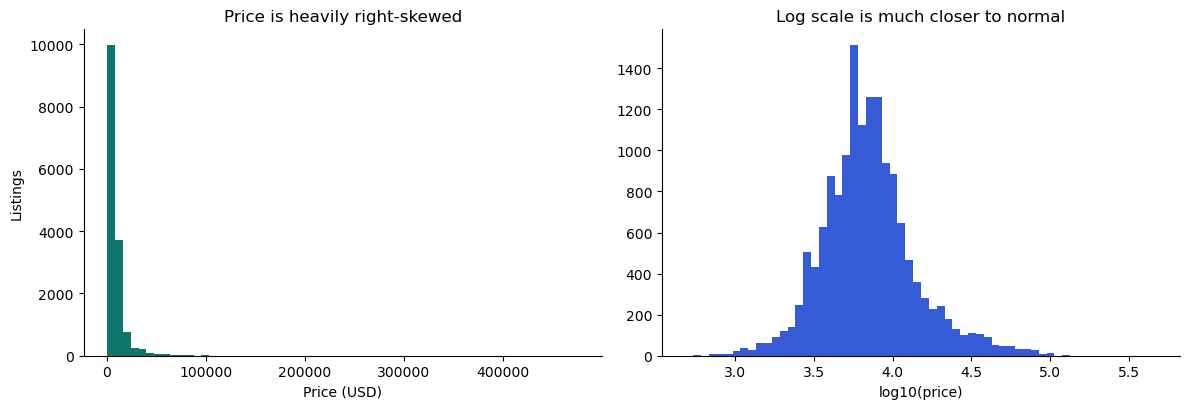

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(cars["price_usd"], bins=60, color="#0f766e")
axes[0].set(title="Price is heavily right-skewed", xlabel="Price (USD)", ylabel="Listings")
axes[1].hist(np.log10(cars["price_usd"]), bins=60, color="#365bd6")
axes[1].set(title="Log scale is much closer to normal", xlabel="log10(price)")
plt.tight_layout(); plt.savefig("../images/price_distribution.png", dpi=150, bbox_inches="tight"); plt.show()

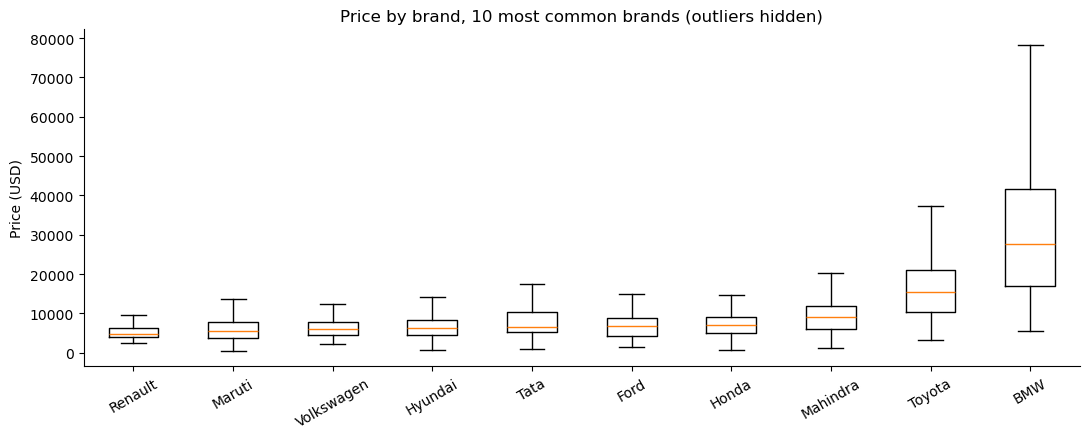

In [7]:
top = cars["brand"].value_counts().head(10).index
order = cars[cars["brand"].isin(top)].groupby("brand")["price_usd"].median().sort_values().index
plt.figure(figsize=(11, 4.5))
plt.boxplot([cars.loc[cars["brand"] == b, "price_usd"] for b in order], showfliers=False)
plt.xticks(range(1, len(order) + 1), order, rotation=30)
plt.title("Price by brand, 10 most common brands (outliers hidden)"); plt.ylabel("Price (USD)")
plt.tight_layout(); plt.savefig("../images/price_by_brand.png", dpi=150, bbox_inches="tight"); plt.show()

In [8]:
cars.select_dtypes("number").corr()["price_usd"].drop("price_usd").sort_values(ascending=False).round(3)

max_power      0.751
engine         0.586
seats          0.115
km_driven     -0.118
vehicle_age   -0.241
mileage       -0.305
Name: price_usd, dtype: float64

Max power is the strongest single driver of price; vehicle age and mileage pull price down.

## 4. Train/test split
The split is stratified by price band so cheap and expensive cars are represented equally in both sets. The test set is not touched again until the final evaluation.

In [9]:
cars["price_band"] = pd.qcut(cars["price_usd"], q=5, labels=False)
train, test = train_test_split(cars, test_size=0.2, stratify=cars["price_band"], random_state=RANDOM_STATE)

drop = ["price_usd", "price_band", "model"]
X_train, y_train = train.drop(columns=drop), train["price_usd"]
X_test,  y_test  = test.drop(columns=drop),  test["price_usd"]

def add_features(df):
    df = df.copy()
    df["km_per_year"] = df["km_driven"] / (df["vehicle_age"] + 1)
    df["power_per_litre"] = df["max_power"] / (df["engine"] / 1000)
    df["log_km"] = np.log1p(df["km_driven"])
    return df

X_train, X_test = add_features(X_train), add_features(X_test)
num_cols = X_train.select_dtypes("number").columns.tolist()
cat_cols = ["brand", "seller_type", "fuel_type", "transmission_type"]
print(X_train.shape, X_test.shape)

(12185, 13) (3047, 13)


## 5. Leak-free preprocessing pipeline
Imputation, scaling, and encoding are learned **inside** each cross-validation fold, so validation scores are honest.

In [10]:
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20), cat_cols),
])

def cv_scores(model, cv=5):
    s = cross_validate(model, X_train, y_train, cv=cv,
                       scoring=("neg_root_mean_squared_error", "neg_mean_absolute_error", "r2"))
    return {"CV RMSE": -s["test_neg_root_mean_squared_error"].mean(),
            "CV MAE": -s["test_neg_mean_absolute_error"].mean(),
            "CV R²": s["test_r2"].mean()}

log_target = lambda reg: TransformedTargetRegressor(regressor=reg, func=np.log, inverse_func=np.exp)

models = {
    "Baseline (predict the mean)": make_pipeline(preprocess, DummyRegressor()),
    "Linear regression":            make_pipeline(preprocess, LinearRegression()),
    "Linear regression, log price": log_target(make_pipeline(preprocess, LinearRegression())),
    "Ridge, log price":             log_target(make_pipeline(preprocess, Ridge(alpha=1))),
    "Decision tree (depth 12)":     make_pipeline(preprocess, DecisionTreeRegressor(max_depth=12, random_state=RANDOM_STATE)),
}
results = pd.DataFrame({name: cv_scores(m) for name, m in models.items()}).T
results.round({"CV RMSE": 0, "CV MAE": 0, "CV R²": 3}).sort_values("CV RMSE")

,CV RMSE,CV MAE,CV R²
"Linear regression, log price",4214.0,1680.0,0.845
"Ridge, log price",4214.0,1681.0,0.845
Decision tree (depth 12),4659.0,1460.0,0.814
Linear regression,6126.0,2745.0,0.683
Baseline (predict the mean),10839.0,5441.0,-0.001


**Why the log target matters.** Car values fall by a *percentage* each year, not a fixed dollar amount. A straight line on raw price predicts negative prices for some cars; modeling log(price) fixes the shape and cuts error sharply.

Negative price predictions, raw target: 591
Negative price predictions, log target: 0


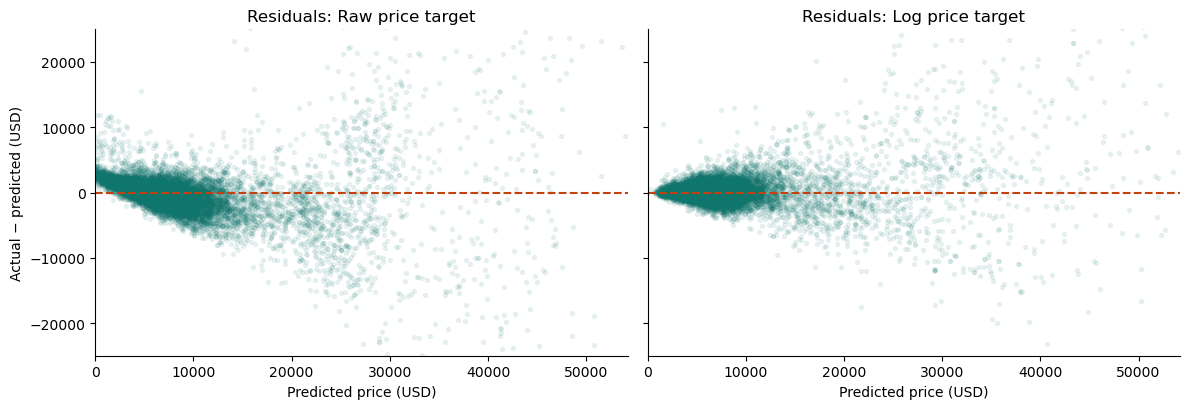

In [11]:
from sklearn.model_selection import cross_val_predict
raw_pred = cross_val_predict(models["Linear regression"], X_train, y_train, cv=5)
log_pred = cross_val_predict(models["Linear regression, log price"], X_train, y_train, cv=5)
print("Negative price predictions, raw target:", int((raw_pred < 0).sum()))
print("Negative price predictions, log target:", int((log_pred < 0).sum()))

lim = y_train.quantile(0.99)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, pred, title in zip(axes, [raw_pred, log_pred], ["Raw price target", "Log price target"]):
    ax.scatter(pred, y_train - pred, alpha=0.08, s=8, color="#0f766e")
    ax.axhline(0, color="#c2410c", ls="--"); ax.set_xlim(0, lim); ax.set_ylim(-25000, 25000)
    ax.set(title=f"Residuals: {title}", xlabel="Predicted price (USD)")
axes[0].set_ylabel("Actual − predicted (USD)")
plt.tight_layout(); plt.savefig("../images/residuals_raw_vs_log.png", dpi=150, bbox_inches="tight"); plt.show()

## 6. Tune on training data only

In [12]:
ridge_search = GridSearchCV(log_target(make_pipeline(preprocess, Ridge())),
                            {"regressor__ridge__alpha": [0.1, 1, 10, 100]},
                            cv=5, scoring="neg_root_mean_squared_error").fit(X_train, y_train)
tree_search = GridSearchCV(make_pipeline(preprocess, DecisionTreeRegressor(random_state=RANDOM_STATE)),
                           {"decisiontreeregressor__max_depth": [8, 10, 12, 15],
                            "decisiontreeregressor__min_samples_leaf": [1, 3, 5, 10]},
                           cv=5, scoring="neg_root_mean_squared_error").fit(X_train, y_train)
print("Ridge (log price):", ridge_search.best_params_, f"CV RMSE = ${-ridge_search.best_score_:,.0f}")
print("Decision tree:    ", tree_search.best_params_, f"CV RMSE = ${-tree_search.best_score_:,.0f}")

Ridge (log price): {'regressor__ridge__alpha': 1} CV RMSE = $4,214
Decision tree:     {'decisiontreeregressor__max_depth': 12, 'decisiontreeregressor__min_samples_leaf': 1} CV RMSE = $4,659


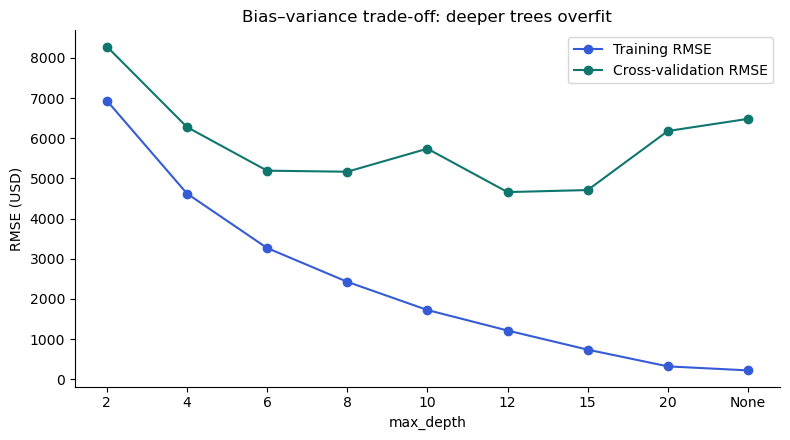

In [13]:
depths = [2, 4, 6, 8, 10, 12, 15, 20, None]
tr, cv = [], []
for d in depths:
    s = cross_validate(make_pipeline(preprocess, DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE)),
                       X_train, y_train, cv=5, scoring="neg_root_mean_squared_error", return_train_score=True)
    tr.append(-s["train_score"].mean()); cv.append(-s["test_score"].mean())
labels = [str(d) for d in depths]
plt.plot(labels, tr, "o-", label="Training RMSE", color="#365bd6")
plt.plot(labels, cv, "o-", label="Cross-validation RMSE", color="#0f766e")
plt.title("Bias–variance trade-off: deeper trees overfit"); plt.xlabel("max_depth"); plt.ylabel("RMSE (USD)"); plt.legend()
plt.tight_layout(); plt.savefig("../images/tree_depth_overfitting.png", dpi=150, bbox_inches="tight"); plt.show()

## 7. Final evaluation on the held-out test set (used once)

In [14]:
best = ridge_search if -ridge_search.best_score_ < -tree_search.best_score_ else tree_search
pred = best.best_estimator_.predict(X_test)
test_scores = {"Test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
               "Test MAE": mean_absolute_error(y_test, pred),
               "Test R²": r2_score(y_test, pred)}
print("Chosen model:", "Ridge on log price" if best is ridge_search else "Decision tree")
for k, v in test_scores.items():
    print(f"{k:10} {v:,.3f}" if "R²" in k else f"{k:10} ${v:,.0f}")

Chosen model: Ridge on log price
Test RMSE  $3,810
Test MAE   $1,740
Test R²    0.857


The test score is close to the cross-validation score, so the model generalizes well rather than memorizing the training data.

## 8. Classification: will this car sell in the premium segment?
A car is labelled **premium** if its price is above $10,000.

In [15]:
y_train_c = (y_train > 10_000).astype(int)
y_test_c = (y_test > 10_000).astype(int)
print(f"Premium share in training data: {y_train_c.mean():.1%}")

def cv_clf(model):
    s = cross_validate(make_pipeline(preprocess, model), X_train, y_train_c, cv=5,
                       scoring=["accuracy", "precision", "recall", "f1"])
    return {m: s[f"test_{m}"].mean() for m in ["accuracy", "precision", "recall", "f1"]}

classifiers = {
    "Baseline (majority class)": DummyClassifier(),
    "Logistic regression": LogisticRegression(max_iter=2000),
    "Decision tree (depth 5)": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "k-NN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Random forest": RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}
import warnings; warnings.filterwarnings("ignore", category=UserWarning)
clf_results = pd.DataFrame({n: cv_clf(m) for n, m in classifiers.items()}).T.round(3)
clf_results.sort_values("f1", ascending=False)

Premium share in training data: 24.4%


,accuracy,precision,recall,f1
Gradient boosting,0.946,0.894,0.883,0.889
Random forest,0.945,0.893,0.882,0.887
Logistic regression,0.939,0.899,0.844,0.870
k-NN (k=5),0.937,0.888,0.848,0.867
Decision tree (depth 5),0.930,0.880,0.827,0.851
Baseline (majority class),0.756,0.000,0.000,0.000


Best settings: {'gradientboostingclassifier__learning_rate': 0.1, 'gradientboostingclassifier__max_depth': 5} | CV F1 = 0.896
Test accuracy 0.947 | precision 0.881 | recall 0.897 | F1 0.889


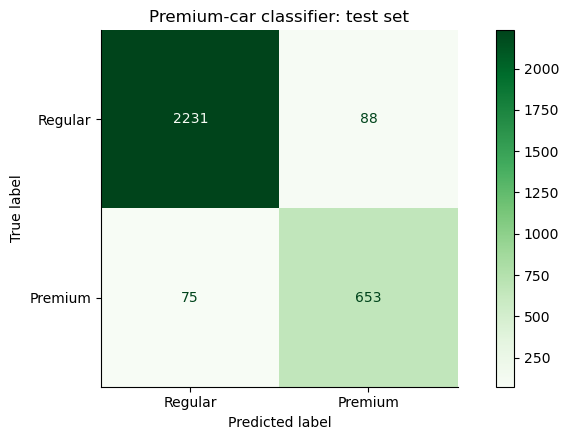

In [16]:
gb_search = GridSearchCV(make_pipeline(preprocess, GradientBoostingClassifier(random_state=RANDOM_STATE)),
                         {"gradientboostingclassifier__max_depth": [3, 5],
                          "gradientboostingclassifier__learning_rate": [0.1, 0.2]},
                         cv=3, scoring="f1", n_jobs=-1).fit(X_train, y_train_c)
pred_c = gb_search.predict(X_test)
print("Best settings:", gb_search.best_params_, f"| CV F1 = {gb_search.best_score_:.3f}")
print(f"Test accuracy {accuracy_score(y_test_c, pred_c):.3f} | precision {precision_score(y_test_c, pred_c):.3f} | "
      f"recall {recall_score(y_test_c, pred_c):.3f} | F1 {f1_score(y_test_c, pred_c):.3f}")
ConfusionMatrixDisplay.from_predictions(y_test_c, pred_c, display_labels=["Regular", "Premium"], cmap="Greens")
plt.title("Premium-car classifier: test set"); plt.tight_layout()
plt.savefig("../images/premium_confusion_matrix.png", dpi=150, bbox_inches="tight"); plt.show()

## 9. Findings
- **Data preparation mattered:** removing duplicates and impossible values, and treating zero seats as missing, gave the models clean, honest inputs.
- **Model shape mattered more than model complexity:** switching to a log-price target was the single biggest improvement and eliminated negative price predictions.
- **The final regression model generalizes:** test performance closely matches cross-validation.
- **Premium cars can be flagged reliably** with a tuned gradient boosting classifier.

**Limitations and next steps:** prices come from one Indian marketplace and a fixed exchange rate; adding listing date, location, and condition would likely improve accuracy, and a gradient-boosted regressor could be tested against the Ridge model.